In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import (KFold, GroupKFold, RandomizedSearchCV, GroupShuffleSplit, ShuffleSplit,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from xgboost import XGBRegressor

from sklearn.inspection import permutation_importance

import shap

# # ----------------------------------------------------------------------------
# # 0. SETUP
# # ----------------------------------------------------------------------------
TARGET = "10cm_area"
GROUP_COL = None          # e.g. "catchment_id" / "cell_id" -- STRONGLY recommended if spatial/temporal autocorrelation
# LOG_TARGET = False        # set True if the target is right-skewed / spans orders of magnitude
SEED = 42
# N_OUTER, N_INNER, N_ITER = 5, 3, 40
# N_JOBS = -1

from PrepDataFunctions import *

### Prepare data

In [3]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl", 
                        remove_events_with_zero_flooding = False)
df = df[df['mean_sm_2_before_event'].notna()]

subset_early = create_temporal_subset(df, "before", 2020)
subset_early = subset_early[subset_early['10cm_area']>0.05]
print(len(subset_early))
subset_early = subset_early[subset_early['y_coord'] < 560000]
# subset_early = subset_early[subset_early['peak_cell_inside_prop'] ==100]
print(len(subset_early))

20190
17381


### Define variables

In [4]:
predictor_variables = ['max_precip', 'total_acc',  
                       "hc_at_peak", 'fumax_at_peak', 
                      'se_max', 'se_min',  'sat_at_peak_new', 'sat_at_peak_old',
                      'fu_mean_m',  'fu_min_m', 'fu_max_m', 'fu_at_peak_new', 
                        "mean_sm_2_before_event",
         'peak_position_ratio_n','d50_n','gini_n','time_based_std_n','dry_ratio_n','max_quartile_index_n',                     
                      'peak_cell_slope_avg', 'peak_cell_elev_avg','peak_cell_elev_min','peak_cell_slope_max', 
                       'peak_cell_water_prop', 'peak_cell_urban_prop',
                       #'peak_cell_inside_prop',
           'cluster_n_cells_t50', 'cluster_n_cells_t80',
                      "random_variable"]

X = subset_early[predictor_variables]
y = subset_early[TARGET].values

--------------------------------------------------
###  2. Identify grouped and individual predictors
--------------------------------------------------

In [5]:
variable_groups = {'Soil Saturation': ['sat_at_peak_new', 'sat_at_peak_old','fu_at_peak_new', 'mean_sm_2_before_event'],
                    'Cell slope': ['peak_cell_slope_avg', 'peak_cell_slope_max'],'Cell capacity to hold water': [
        'hc_at_peak', 'fumax_at_peak', 'peak_cell_urban_prop'],
                'Rainfall temporal profile': [
        'peak_position_ratio_n', 'd50_n', 'max_quartile_index_n']}

grouped_variables = {col for cols in variable_groups.values() for col in cols}
individual_variables = [col for col in X.columns if col not in grouped_variables]

--------------------------------------------------
###  Fit model
--------------------------------------------------

In [6]:
# rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=SEED)
rf = RandomForestRegressor(n_estimators=100,max_depth=8,random_state=42)

# 1. PERFORMANCE: 5-fold CV, every prediction comes from a model that never saw that row
cv = KFold(5, shuffle=True, random_state=SEED)
oof = cross_val_predict(rf, X, y, cv=cv)
print(f"CV R2 = {r2_score(y, oof):.3f}, RMSE = {np.sqrt(mean_squared_error(y, oof)):.3f}")

# 2. IMPORTANCE: fit on 75% of the data, explain the model on the unseen 25%
splitter = ShuffleSplit(1, test_size=0.25, random_state=SEED)
tr, te = next(splitter.split(X, y))
rf.fit(X.iloc[tr], y[tr])
print(f"Hold-out R2 (for reference) = {rf.score(X.iloc[te], y[te]):.3f}")

CV R2 = 0.725, RMSE = 0.297
Hold-out R2 (for reference) = 0.723


### Feature importance

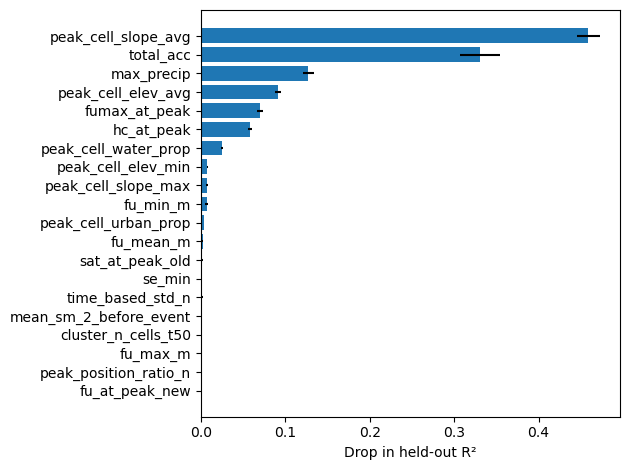

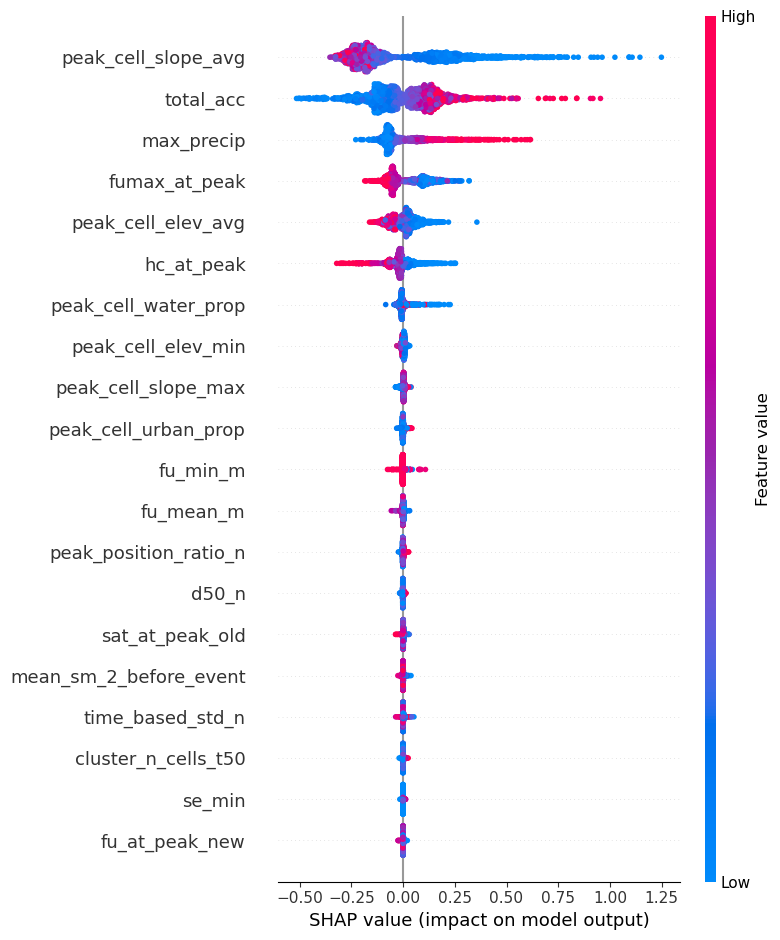

In [7]:
# 2a. Permutation importance (drop in R2 when a feature is shuffled)
pi = permutation_importance(rf, X.iloc[te], y[te], n_repeats=20, random_state=SEED, n_jobs=-1)
perm = pd.DataFrame({"mean": pi.importances_mean, "sd": pi.importances_std}, index=X.columns).sort_values("mean", ascending=False)
# print(perm.round(4).head(20))
top = perm.head(20)[::-1]
plt.barh(top.index, top["mean"], xerr=top["sd"]); plt.xlabel("Drop in held-out R²"); plt.tight_layout(); plt.show()

# 2b. SHAP (direction and size of each feature's effect)
Xte = X.iloc[te].sample(min(2000, len(te)), random_state=SEED)
sv = shap.TreeExplainer(rf).shap_values(Xte)
shap.summary_plot(sv, Xte, max_display=20)

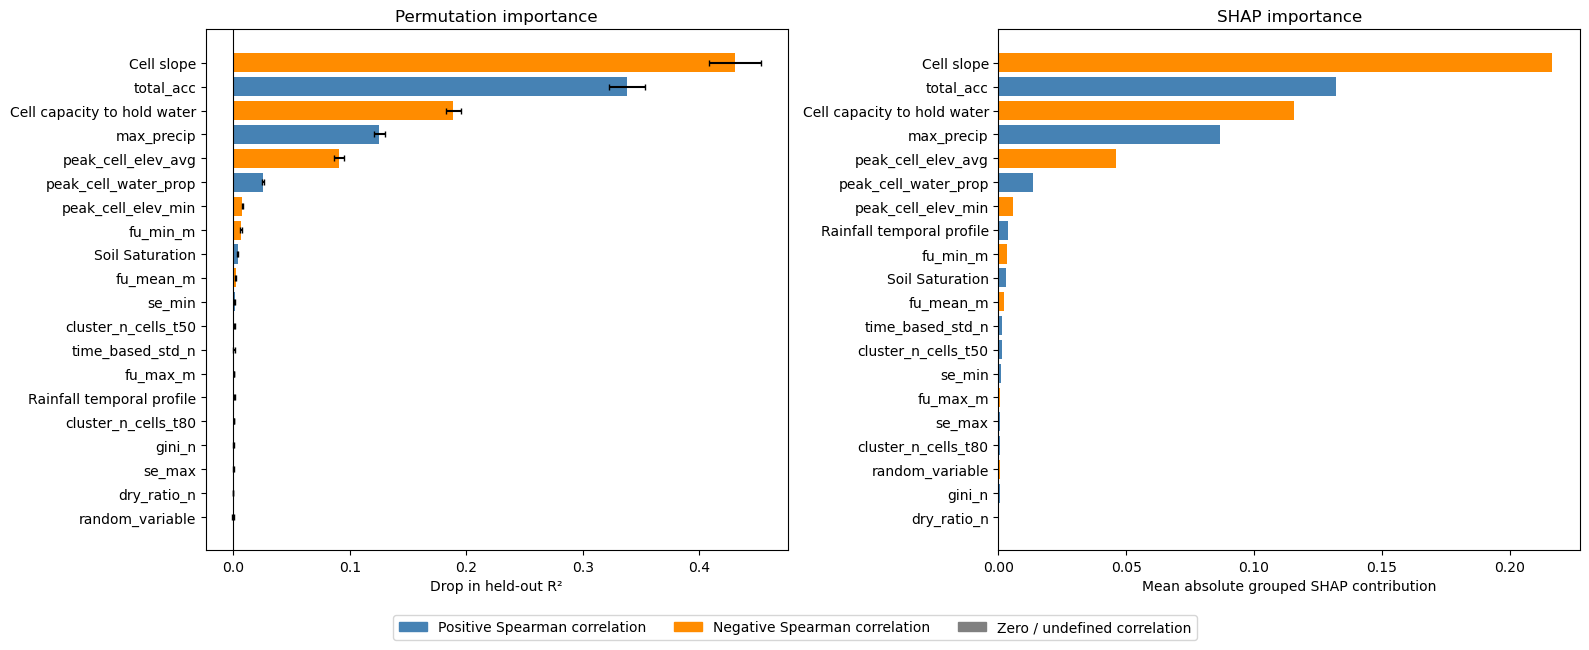

In [8]:
# --------------------------------------------------
# 3. Fit model on training data 
# --------------------------------------------------
X_train = X.iloc[tr]
X_test = X.iloc[te]
y_train, y_test = y[tr], y[te]

# --------------------------------------------------
# 4. Permutation importance (PI)
# --------------------------------------------------
baseline_r2 = rf.score(X_test, y_test)
rng = np.random.default_rng(SEED)
n_repeats = 20

pi_results = []

# Individual predictors: shuffle one column at a time
for col in individual_variables:
    drops = []
    for _ in range(n_repeats):
        X_perm = X_test.copy()
        X_perm[col] = rng.permutation(X_perm[col].to_numpy())
        drops.append(baseline_r2 - rf.score(X_perm, y_test))

    pi_results.append({"predictor": col,"PI_mean": np.mean(drops),"PI_sd": np.std(drops, ddof=1)})

# Groups: shuffle all columns together using the same row permutation
for group_name, variables in variable_groups.items():
    cols = [col for col in variables if col in X.columns]
    if not cols:
        continue

    drops = []
    for _ in range(n_repeats):
        X_perm = X_test.copy()
        perm_idx = rng.permutation(len(X_test))
        X_perm.loc[:, cols] = X_test[cols].iloc[perm_idx].to_numpy()
        drops.append(baseline_r2 - rf.score(X_perm, y_test))

    pi_results.append({"predictor": group_name,"PI_mean": np.mean(drops),"PI_sd": np.std(drops, ddof=1)})

pi_df = pd.DataFrame(pi_results).sort_values("PI_mean", ascending=False)

# print("\nPermutation importance:")
# print(pi_df.round(4).to_string(index=False))

# --------------------------------------------------
# 5. SHAP values
# --------------------------------------------------
X_shap = X_test.sample(min(2000, len(X_test)), random_state=SEED)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_shap)

shap_df = pd.DataFrame(
    shap_values,
    columns=X_shap.columns,
    index=X_shap.index)

shap_results = []

# Individual predictors: mean absolute SHAP
for col in individual_variables:
    shap_results.append({
        "predictor": col,
        "SHAP_mean_abs": shap_df[col].abs().mean()})

# Groups: aggregate SHAP values before taking absolute values
for group_name, variables in variable_groups.items():
    cols = [col for col in variables if col in shap_df.columns]
    if not cols:
        continue

    group_shap = shap_df[cols].sum(axis=1)

    shap_results.append({
        "predictor": group_name,
        "SHAP_mean_abs": group_shap.abs().mean()})

shap_df_grouped = pd.DataFrame(shap_results).sort_values("SHAP_mean_abs", ascending=False)

# print("\nGrouped and individual SHAP importance:")
# print(shap_df_grouped.round(4).to_string(index=False))

# --------------------------------------------------
# 6. Plot PI and SHAP rankings
# --------------------------------------------------
# fig, axes = plt.subplots(1, 2, figsize=(16, max(6, len(pi_df) * 0.32)))

# # PI
# plot_pi = pi_df.sort_values("PI_mean")
# axes[0].barh(plot_pi["predictor"], plot_pi["PI_mean"],
#              xerr=plot_pi["PI_sd"], capsize=2)
# axes[0].axvline(0, color="black", linewidth=0.8)
# axes[0].set_xlabel("Drop in held-out R²")
# axes[0].set_title("Permutation importance")

# # SHAP
# plot_shap = shap_df_grouped.sort_values("SHAP_mean_abs")
# axes[1].barh(plot_shap["predictor"], plot_shap["SHAP_mean_abs"])
# axes[1].set_xlabel("Mean absolute grouped SHAP contribution")
# axes[1].set_title("SHAP importance")

# fig.tight_layout()
# plt.show()

from scipy.stats import spearmanr
from matplotlib.patches import Patch

# Map each predictor/group to the sign of its Spearman correlation
predictor_corr = {}
data=subset_early
for predictor in pi_df["predictor"]:
    if predictor in variable_groups:  # Grouped predictor
        cols = [c for c in variable_groups[predictor] if c in data.columns]
        rhos = [spearmanr(data[c], data[TARGET], nan_policy="omit").statistic for c in cols]
        rho = np.nanmean(rhos) if rhos else np.nan
    else:  # Individual predictor
        if predictor in data.columns:
            rho = spearmanr(data[predictor], data[TARGET], nan_policy="omit").statistic
        else:
            rho = np.nan
    predictor_corr[predictor] = rho

# Colours: positive = blue, negative = orange, zero/undefined = grey
def corr_colour(predictor):
    rho = predictor_corr.get(predictor, np.nan)
    return "steelblue" if rho > 0 else "darkorange" if rho < 0 else "grey"

# PI
fig, axes = plt.subplots(1, 2, figsize=(16, max(6, len(pi_df) * 0.32)))

plot_pi = pi_df.sort_values("PI_mean")
axes[0].barh(plot_pi["predictor"], plot_pi["PI_mean"], xerr=plot_pi["PI_sd"], capsize=2,
             color=[corr_colour(p) for p in plot_pi["predictor"]])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Drop in held-out R²")
axes[0].set_title("Permutation importance")

# SHAP
plot_shap = shap_df_grouped.sort_values("SHAP_mean_abs")
axes[1].barh(plot_shap["predictor"], plot_shap["SHAP_mean_abs"],
             color=[corr_colour(p) for p in plot_shap["predictor"]])
axes[1].set_xlabel("Mean absolute grouped SHAP contribution")
axes[1].set_title("SHAP importance")

# Shared legend
legend_handles = [
    Patch(color="steelblue", label="Positive Spearman correlation"),
    Patch(color="darkorange", label="Negative Spearman correlation"),
    Patch(color="grey", label="Zero / undefined correlation")
]
fig.legend(handles=legend_handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

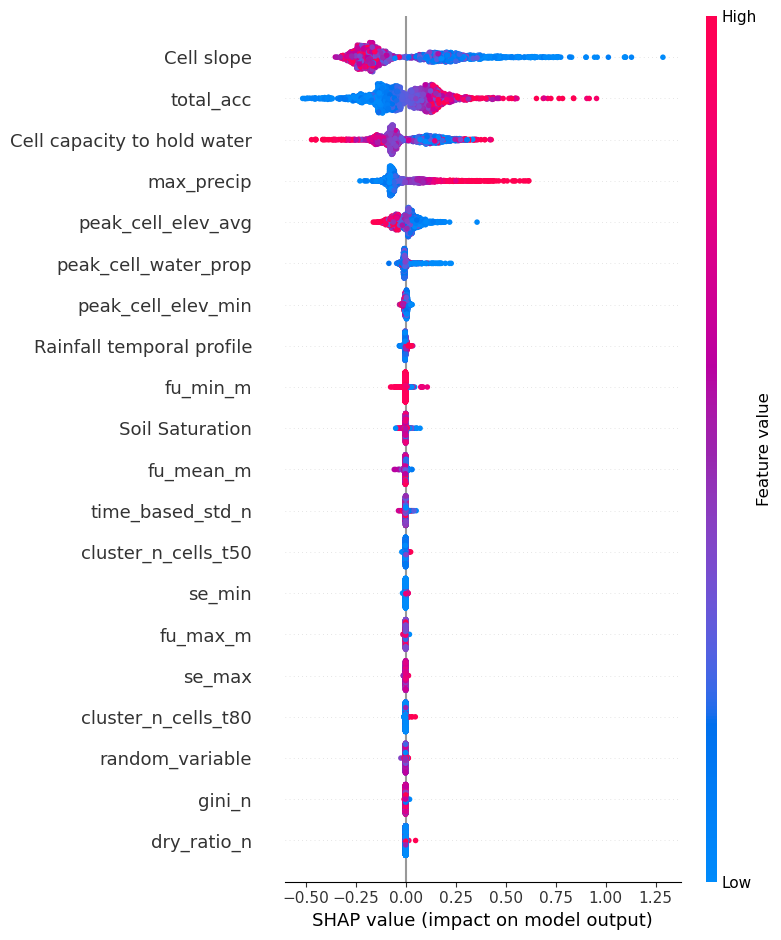

In [9]:
# --------------------------------------------------
# 7. Grouped SHAP beeswarm plot
# --------------------------------------------------
grouped_shap_values = pd.DataFrame(index=shap_df.index)

# Keep individual predictors
for col in individual_variables:
    grouped_shap_values[col] = shap_df[col]

# Aggregate SHAP values for each group
for group_name, variables in variable_groups.items():
    cols = [col for col in variables if col in shap_df.columns]
    if cols:
        grouped_shap_values[group_name] = shap_df[cols].sum(axis=1)

# Matching feature values for beeswarm colouring
# Individual predictors retain their original values.
# Grouped predictors use the mean of their component values
grouped_feature_values = X_shap[individual_variables].copy()

for group_name, variables in variable_groups.items():
    cols = [col for col in variables if col in X_shap.columns]
    if cols:
        grouped_feature_values[group_name] = X_shap[cols].mean(axis=1)

# Order by mean absolute grouped SHAP
shap_order = grouped_shap_values.abs().mean().sort_values(ascending=False).index

grouped_shap_values = grouped_shap_values[shap_order]
grouped_feature_values = grouped_feature_values[shap_order]

# Beeswarm
shap.summary_plot(
    grouped_shap_values.to_numpy(),
    grouped_feature_values,
    feature_names=grouped_shap_values.columns.tolist(),
    max_display=20,
    show=True)

In [ ]:
# data = df[predictor_variables + [TARGET] + ([GROUP_COL] if GROUP_COL else [])].dropna(subset=[TARGET])
# X = data[predictor_variables]
# y = data[TARGET].values
# groups = data[GROUP_COL].values if GROUP_COL else None

# print(f"n = {len(X)}, p = {X.shape[1]}")
# print(y.shape, pd.Series(y).describe().round(3).to_dict())
# print("Missing values per predictor (top):\n", X.isna().sum().sort_values(ascending=False).head())

# def get_cv(n_splits):
#     """Group-aware CV if groups given (prevents leakage), otherwise shuffled KFold."""
#     return GroupKFold(n_splits=n_splits) if GROUP_COL else KFold(n_splits, shuffle=True, random_state=SEED)

# def split(cv, X, y, groups):
#     return cv.split(X, y, groups) if GROUP_COL else cv.split(X, y)

# def wrap(model):
#     """Optionally model log1p(target); predictions are back-transformed automatically."""
#     return TransformedTargetRegressor(model, func=np.log1p, inverse_func=np.expm1) if LOG_TARGET else model

# def prefix(params):
#     return {f"regressor__{k}": v for k, v in params.items()} if LOG_TARGET else params

# # ----------------------------------------------------------------------------
# # 1. QUICK MODEL COMPARISON (default hyperparameters, repeated CV)
# #    Purpose: choose model family, NOT report final performance.
# # ----------------------------------------------------------------------------
# candidates = {
#     "Dummy (mean)": DummyRegressor(),
#     "Ridge (linear baseline)": make_pipeline(SimpleImputer(), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 20))),
#     "RandomForest": make_pipeline(SimpleImputer(), RandomForestRegressor(n_estimators=300, n_jobs=N_JOBS, random_state=SEED)),
#     "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
#                             colsample_bytree=0.8, n_jobs=N_JOBS, random_state=SEED),  # handles NaN natively
# }
# scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

# rows = []
# for name, m in candidates.items():
#     cv = get_cv(N_OUTER)
#     res = cross_validate(wrap(m), X, y, groups=groups, cv=cv, scoring=scoring, n_jobs=1)
#     rows.append({"model": name,
#                  "R2": res["test_r2"].mean(), "R2_sd": res["test_r2"].std(),
#                  "RMSE": -res["test_rmse"].mean(), "MAE": -res["test_mae"].mean()})
# comparison = pd.DataFrame(rows).set_index("model").round(3)
# print("\nBaseline model comparison:\n", comparison)

# # ----------------------------------------------------------------------------
# # 2. HYPERPARAMETER SEARCH SPACES
# # ----------------------------------------------------------------------------
# rf_space = {
#     "n_estimators": [300, 500, 800],
#     "max_depth": [None, 6, 10, 16, 24],
#     "min_samples_leaf": [1, 2, 5, 10, 20],      # most important regulariser for RF
#     "max_features": [0.2, 0.33, 0.5, 0.75, 1.0],
#     "max_samples": [0.5, 0.7, 0.9, None],
# }
# xgb_space = {
#     "n_estimators": [200, 400, 800],
#     "learning_rate": [0.01, 0.03, 0.05, 0.1],
#     "max_depth": [3, 4, 6, 8],
#     "min_child_weight": [1, 5, 10],
#     "subsample": [0.6, 0.8, 1.0],
#     "colsample_bytree": [0.5, 0.7, 1.0],
#     "reg_lambda": [0.1, 1, 10],
# }

# def make_search(kind, inner_cv):
#     if kind == "rf":
#         base = make_pipeline(SimpleImputer(), RandomForestRegressor(random_state=SEED, n_jobs=1))
#         space = {f"randomforestregressor__{k}": v for k, v in rf_space.items()}
#     else:
#         base = XGBRegressor(random_state=SEED, n_jobs=1)
#         space = xgb_space
#     if LOG_TARGET:
#         base = TransformedTargetRegressor(base, func=np.log1p, inverse_func=np.expm1)
#         space = {f"regressor__{k}": v for k, v in space.items()}
#     return RandomizedSearchCV(base, space, n_iter=N_ITER, cv=inner_cv,
#                               scoring="neg_root_mean_squared_error",
#                               n_jobs=N_JOBS, random_state=SEED, refit=True)

# # ----------------------------------------------------------------------------
# # 3. NESTED CV  -> unbiased performance estimate INCLUDING the tuning procedure
# #    Outer loop: estimates generalisation. Inner loop: tunes hyperparameters.
# #    Tuned params may differ per outer fold -- that's expected.
# # ----------------------------------------------------------------------------
# def nested_cv(kind):
#     outer = get_cv(N_OUTER)
#     oof_pred = np.full(len(y), np.nan)
#     fold_scores, fold_best = [], []
#     for k, (tr, te) in enumerate(split(outer, X, y, groups)):
#         inner = get_cv(N_INNER)
#         search = make_search(kind, inner)
#         fit_kw = {}
#         if GROUP_COL:   # inner splits must respect groups too
#             inner_splits = list(inner.split(X.iloc[tr], y[tr], groups[tr]))
#             search.set_params(cv=inner_splits)
#         search.fit(X.iloc[tr], y[tr])
#         pred = search.predict(X.iloc[te])
#         oof_pred[te] = pred
#         fold_scores.append({"fold": k, "R2": r2_score(y[te], pred),
#                             "RMSE": np.sqrt(mean_squared_error(y[te], pred)),
#                             "MAE": mean_absolute_error(y[te], pred)})
#         fold_best.append(search.best_params_)
#         print(f"[{kind}] outer fold {k}: R2={fold_scores[-1]['R2']:.3f}")
#     return pd.DataFrame(fold_scores), oof_pred, fold_best

# nested = {}
# for kind in ["rf"]:
#     scores, oof, best = nested_cv(kind)
#     nested[kind] = dict(scores=scores, oof=oof, best=best)
#     s = scores[["R2", "RMSE", "MAE"]]
#     print(f"\n{kind.upper()} nested-CV performance (mean ± sd across outer folds):")
#     print(pd.DataFrame({"mean": s.mean(), "sd": s.std()}).round(3))

# # ----------------------------------------------------------------------------
# # 4. OBSERVED vs PREDICTED & RESIDUALS (out-of-fold predictions only)
# # ----------------------------------------------------------------------------
# oof = nested["rf"]["oof"]
# fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
# ax[0].scatter(y, oof, s=8, alpha=0.4)
# lims = [min(y.min(), oof.min()), max(y.max(), oof.max())]
# ax[0].plot(lims, lims, "k--"); ax[0].set(xlabel="Observed", ylabel="Predicted (out-of-fold)", title="RF nested CV")
# ax[1].scatter(oof, y - oof, s=8, alpha=0.4); ax[1].axhline(0, c="k", ls="--")
# ax[1].set(xlabel="Predicted", ylabel="Residual", title="Residuals")
# plt.tight_layout(); plt.show()

# # ----------------------------------------------------------------------------
# # 5. FINAL MODEL: tune on ALL data (CV only), then refit -> used for deployment/importance
# # ----------------------------------------------------------------------------
# final_cv = get_cv(N_OUTER)
# final_search = make_search("rf", list(split(final_cv, X, y, groups)))
# final_search.fit(X, y)
# final_rf = final_search.best_estimator_
# print("\nFinal RF params:", final_search.best_params_)

# # ----------------------------------------------------------------------------
# # 6. FEATURE IMPORTANCE
# #    (a) Permutation importance on HELD-OUT folds (not training data -> avoids bias towards
# #        high-cardinality/noisy features that impurity importance suffers from)
# # ----------------------------------------------------------------------------
# perm_rows = []
# for k, (tr, te) in enumerate(split(get_cv(N_OUTER), X, y, groups)):
#     m = clone(final_rf).fit(X.iloc[tr], y[tr])
#     pi = permutation_importance(m, X.iloc[te], y[te], n_repeats=20, scoring="r2",
#                                 random_state=SEED, n_jobs=N_JOBS)
#     perm_rows.append(pd.DataFrame({"feature": predictor_variables, "fold": k, "importance": pi.importances_mean}))
# perm = pd.concat(perm_rows)
# perm_summary = (perm.groupby("feature")["importance"].agg(["mean", "std"])
#                 .sort_values("mean", ascending=False))
# print("\nPermutation importance (drop in R2 on held-out data):\n", perm_summary.round(4))

# top = perm_summary.head(20)[::-1]
# plt.figure(figsize=(6, 0.3 * len(top) + 1.5))
# plt.barh(top.index, top["mean"], xerr=top["std"])
# plt.xlabel("Mean drop in held-out R²"); plt.title("Permutation importance (RF)")
# plt.tight_layout(); plt.show()

# # (b) Correlated predictors split/mask importance -> check collinearity before interpreting
# corr = X.corr(method="spearman").abs()
# pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
#          .loc[lambda s: s > 0.8].sort_values(ascending=False))
# print("\nHighly correlated pairs (|rho| > 0.8):\n", pairs.head(15))

# # (c) Partial dependence of the top features (direction/shape of effects)
# top_feats = perm_summary.index[:4].tolist()
# PartialDependenceDisplay.from_estimator(final_rf, X, top_feats, kind="average", n_jobs=N_JOBS)
# plt.tight_layout(); plt.show()

# # (d) Optional: SHAP (pip install shap) -- local + global, handles interactions better
# # import shap
# # rf_core = final_rf.named_steps["randomforestregressor"]
# # Xt = final_rf[:-1].transform(X)
# # sv = shap.TreeExplainer(rf_core).shap_values(Xt[:2000])
# # shap.summary_plot(sv, pd.DataFrame(Xt[:2000], columns=predictor_variables))